# Importing Libraries

In [5]:
import os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.utils.class_weight import compute_class_weight
import tensorflow as tf
from keras.preprocessing.image import ImageDataGenerator
from keras.applications import MobileNetV2
from keras.models import Model
from keras.layers import Dense, Dropout, GlobalAveragePooling2D
from keras.callbacks import (ModelCheckpoint,
                             EarlyStopping,
                             ReduceLROnPlateau)
from keras.optimizers import Adam

print(f"TensorFlow version : {tf.__version__}")
print("All libraries imported successfully!")

TensorFlow version : 2.13.0
All libraries imported successfully!


# Defining Paths & Settings

In [6]:
PROCESSED_PATH = Path("../dataset/processed")
SAVED_MODELS   = Path("../saved_models")
RESULTS_PATH   = Path("../results")

CLASSES   = ["healthy", "leaf_rust", "stripe_rust", "powdery_mildew"]
IMG_SIZE  = (224, 224)
BATCH     = 32
EPOCHS    = 30
LR        = 0.0001

print(f"Processed path : {PROCESSED_PATH}")
print(f"Classes        : {CLASSES}")
print(f"Image size     : {IMG_SIZE}")
print(f"Batch size     : {BATCH}")
print(f"Max epochs     : {EPOCHS}")
print(f"Learning rate  : {LR}")

Processed path : ..\dataset\processed
Classes        : ['healthy', 'leaf_rust', 'stripe_rust', 'powdery_mildew']
Image size     : (224, 224)
Batch size     : 32
Max epochs     : 30
Learning rate  : 0.0001


# Data Augmentation & Loading

In [7]:
# Training data — with augmentation
train_datagen = ImageDataGenerator(
    rescale=1.0/255,
    rotation_range=20,
    width_shift_range=0.1,
    height_shift_range=0.1,
    horizontal_flip=True,
    zoom_range=0.15,
    brightness_range=[0.8, 1.2],
    fill_mode="nearest"
)

# Validation & Test — NO augmentation, only rescale
val_test_datagen = ImageDataGenerator(rescale=1.0/255)

# Load train
train_gen = train_datagen.flow_from_directory(
    PROCESSED_PATH / "train",
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=True,
    seed=42
)

# Load val
val_gen = val_test_datagen.flow_from_directory(
    PROCESSED_PATH / "val",
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=False
)

# Load test
test_gen = val_test_datagen.flow_from_directory(
    PROCESSED_PATH / "test",
    target_size=IMG_SIZE,
    batch_size=BATCH,
    class_mode="categorical",
    classes=CLASSES,
    shuffle=False
)

print(f"\nClass indices : {train_gen.class_indices}")
print(f"Train batches : {len(train_gen)}")
print(f"Val batches   : {len(val_gen)}")
print(f"Test batches  : {len(test_gen)}")

Found 2978 images belonging to 4 classes.
Found 636 images belonging to 4 classes.
Found 643 images belonging to 4 classes.

Class indices : {'healthy': 0, 'leaf_rust': 1, 'stripe_rust': 2, 'powdery_mildew': 3}
Train batches : 94
Val batches   : 20
Test batches  : 21


# Computing Class Weights

In [8]:
# count training images per class
train_counts = [
    len(list((PROCESSED_PATH / "train" / cls).glob("*.jpg")))
    for cls in CLASSES
]

# total training images
total_train = sum(train_counts)

# compute class weights
class_weights = {}
for i, count in enumerate(train_counts):
    class_weights[i] = total_train / (len(CLASSES) * count)

print("Class weights to fix imbalance:\n")
for i, cls in enumerate(CLASSES):
    print(f"  {cls:<20} : {class_weights[i]:.4f}  ({train_counts[i]} images)")

Class weights to fix imbalance:

  healthy              : 0.6689  (1113 images)
  leaf_rust            : 1.2597  (591 images)
  stripe_rust          : 1.1195  (665 images)
  powdery_mildew       : 1.2225  (609 images)


# Building the Model

In [9]:
# Load MobileNetV2 pre-trained on ImageNet, without top layers
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze base model layers — don't retrain them yet
base_model.trainable = False

# Add our custom top layers for wheat disease classification
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(128, activation="relu")(x)
x = Dropout(0.3)(x)
output = Dense(4, activation="softmax")(x)

# Create final model
model = Model(inputs=base_model.input, outputs=output)

# Compile
model.compile(
    optimizer=Adam(learning_rate=LR),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print(f"Total layers       : {len(model.layers)}")
print(f"Trainable layers   : {sum(1 for l in model.layers if l.trainable)}")
print(f"Frozen layers      : {sum(1 for l in model.layers if not l.trainable)}")
model.summary()

Total layers       : 158
Trainable layers   : 4
Frozen layers      : 154
Model: "model"
__________________________________________________________________________________________________
 Layer (type)                Output Shape                 Param #   Connected to                  
 input_1 (InputLayer)        [(None, 224, 224, 3)]        0         []                            
                                                                                                  
 Conv1 (Conv2D)              (None, 112, 112, 32)         864       ['input_1[0][0]']             
                                                                                                  
 bn_Conv1 (BatchNormalizati  (None, 112, 112, 32)         128       ['Conv1[0][0]']               
 on)                                                                                              
                                                                                                  
 Conv1_relu (ReLU)   

# Defining Callbacks

In [ ]:
callbacks = [

    # Save best model automatically
    ModelCheckpoint(
        filepath=str(SAVED_MODELS / "wheat_disease_model.h5"),
        monitor="val_accuracy",
        save_best_only=True,
        verbose=1
    ),

    # Stop training if val_accuracy doesn't improve for 7 epochs
    EarlyStopping(
        monitor="val_accuracy",
        patience=7,
        restore_best_weights=True,
        verbose=1
    ),

    # Reduce learning rate if val_loss doesn't improve for 3 epochs
    ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.5,
        patience=3,
        min_lr=1e-7,
        verbose=1
    )
]

print("Callbacks defined:")
print("  ✅ ModelCheckpoint - saves best model to saved_models/")
print("  ✅ EarlyStopping   - stops if no improvement for 7 epochs")
print("  ✅ ReduceLROnPlateau - halves LR if stuck for 3 epochs")

Callbacks defined:
  ✅ ModelCheckpoint — saves best model to saved_models/
  ✅ EarlyStopping   — stops if no improvement for 7 epochs
  ✅ ReduceLROnPlateau — halves LR if stuck for 3 epochs


# Training the Model

In [11]:
print("Starting training...\n")
print("=" * 55)

history = model.fit(
    train_gen,
    epochs=EPOCHS,
    validation_data=val_gen,
    class_weight=class_weights,
    callbacks=callbacks,
    verbose=1
)

print("\n" + "=" * 55)
print("Training complete!")
print(f"Best val accuracy : {max(history.history['val_accuracy']):.4f}")
print(f"Epochs ran        : {len(history.history['accuracy'])}")

Starting training...

Epoch 1/30
94/94 [==============================] - ETA: 0s - loss: 1.0793 - accuracy: 0.5537
Epoch 1: val_accuracy improved from -inf to 0.80975, saving model to ..\saved_models\wheat_disease_model.h5


c:\Users\New\AppData\Local\Programs\Python\Python310\lib\site-packages\keras\src\engine\training.py:3000: UserWarning: You are saving your model as an HDF5 file via `model.save()`. This file format is considered legacy. We recommend using instead the native Keras format, e.g. `model.save('my_model.keras')`.
  saving_api.save_model(


94/94 [==============================] - 317s 3s/step - loss: 1.0793 - accuracy: 0.5537 - val_loss: 0.6233 - val_accuracy: 0.8097 - lr: 1.0000e-04
Epoch 2/30
94/94 [==============================] - ETA: 0s - loss: 0.6390 - accuracy: 0.7673
Epoch 2: val_accuracy improved from 0.80975 to 0.84277, saving model to ..\saved_models\wheat_disease_model.h5
94/94 [==============================] - 156s 2s/step - loss: 0.6390 - accuracy: 0.7673 - val_loss: 0.4843 - val_accuracy: 0.8428 - lr: 1.0000e-04
Epoch 3/30
94/94 [==============================] - ETA: 0s - loss: 0.5000 - accuracy: 0.8203
Epoch 3: val_accuracy improved from 0.84277 to 0.86006, saving model to ..\saved_models\wheat_disease_model.h5
94/94 [==============================] - 155s 2s/step - loss: 0.5000 - accuracy: 0.8203 - val_loss: 0.4339 - val_accuracy: 0.8601 - lr: 1.0000e-04
Epoch 4/30
94/94 [==============================] - ETA: 0s - loss: 0.4404 - accuracy: 0.8385
Epoch 4: val_accuracy improved from 0.86006 to 0.87579,

# Plot Accuracy & Loss Curves

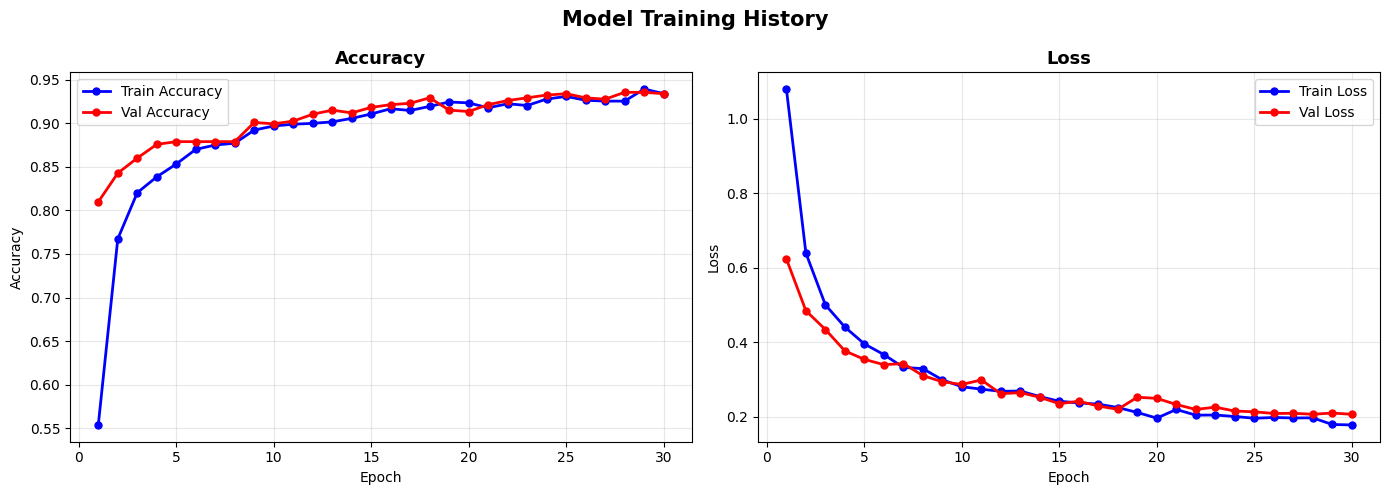

Curves saved to results/accuracy_loss_curves.png


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Model Training History", fontsize=15, fontweight="bold")

epochs_ran = range(1, len(history.history["accuracy"]) + 1)

# Accuracy plot
axes[0].plot(epochs_ran, history.history["accuracy"],
             "b-o", label="Train Accuracy", linewidth=2, markersize=5)
axes[0].plot(epochs_ran, history.history["val_accuracy"],
             "r-o", label="Val Accuracy", linewidth=2, markersize=5)
axes[0].set_title("Accuracy", fontsize=13, fontweight="bold")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Accuracy")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss plot
axes[1].plot(epochs_ran, history.history["loss"],
             "b-o", label="Train Loss", linewidth=2, markersize=5)
axes[1].plot(epochs_ran, history.history["val_loss"],
             "r-o", label="Val Loss", linewidth=2, markersize=5)
axes[1].set_title("Loss", fontsize=13, fontweight="bold")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Loss")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig("../results/accuracy_loss_curves.png", dpi=150)
plt.show()
print("Curves saved to results/accuracy_loss_curves.png")

# To Save Training History & Final Summary

In [13]:
import json

# Save history to JSON
history_data = {
    "accuracy"     : history.history["accuracy"],
    "val_accuracy" : history.history["val_accuracy"],
    "loss"         : history.history["loss"],
    "val_loss"     : history.history["val_loss"]
}

with open("../saved_models/training_history.json", "w") as f:
    json.dump(history_data, f, indent=4)

# Print final summary
print("=" * 55)
print("       TRAINING SUMMARY")
print("=" * 55)
print(f"  Total epochs ran    : {len(history.history['accuracy'])}")
print(f"  Best val accuracy   : {max(history.history['val_accuracy'])*100:.2f}%")
print(f"  Final train acc     : {history.history['accuracy'][-1]*100:.2f}%")
print(f"  Final val acc       : {history.history['val_accuracy'][-1]*100:.2f}%")
print(f"  Model saved to      : saved_models/wheat_disease_model.h5")
print(f"  History saved to    : saved_models/training_history.json")
print("=" * 55)
print("  Training complete. Proceed to Notebook 04.")
print("=" * 55)

       TRAINING SUMMARY
  Total epochs ran    : 30
  Best val accuracy   : 93.55%
  Final train acc     : 93.42%
  Final val acc       : 93.40%
  Model saved to      : saved_models/wheat_disease_model.h5
  History saved to    : saved_models/training_history.json
  Training complete. Proceed to Notebook 04.
